# Tahap 2: Profiling, Cleansing, dan Deteksi Outlier
**Project Akhir Data Wrangling: Indeks Risiko Bencana Terpadu Kab/Kota di Jawa**

Input: `data/interim/tahap1_master.csv` (hasil tahap 1, 100 kab/kota). Tidak perlu upload data mentah lagi.
Output: `data/interim/tahap2_clean.csv` (data bersih plus kolom penanda outlier) dan `data/interim/laporan_kualitas_data.csv`.

Alur: profiling, aturan validasi, standardisasi string, penanganan missing value, deteksi outlier univariat dan multivariat, lalu laporan kualitas data sebelum vs sesudah.

In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

IN = Path("data/interim/quake care gap.csv")
OUT = Path("data/interim"); OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("quake care gap.csv")
sebelum = df.copy()

FITUR = ["n_gempa_50km", "n_gempa_100km", "n_gempa_150km", "mag_max_100km", "kedalaman_rata_100km",
         "energi_rel_100km", "karhutla_total_2018_2025", "gfw_extent_2000_ha", "gfw_loss_2018_2025_ha",
         "gfw_loss_rasio", "pop_total", "prop_anak_0_14", "prop_lansia_65", "n_puskesmas", "n_rs",
         "faskes_per_100k", "irbi_skor"]
KOL_KARHUTLA = [c for c in df.columns if c.startswith("karhutla_20")]
print(df.shape)

(100, 35)


## 1. Profiling awal

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CC_2                      100 non-null    int64  
 1   NAME_1                    100 non-null    object 
 2   NAME_2                    100 non-null    object 
 3   TYPE_2                    100 non-null    object 
 4   lon_c                     100 non-null    float64
 5   lat_c                     100 non-null    float64
 6   n_gempa_50km              100 non-null    int64  
 7   n_gempa_100km             100 non-null    int64  
 8   n_gempa_150km             100 non-null    int64  
 9   mag_max_100km             100 non-null    float64
 10  kedalaman_rata_100km      100 non-null    float64
 11  energi_rel_100km          100 non-null    float64
 12  n_gempa_dalam_polygon     100 non-null    int64  
 13  karhutla_2018             100 non-null    float64
 14  karhutla_20

In [35]:
profil = pd.DataFrame({
    "tipe": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "persen_missing": (df.isna().mean() * 100).round(1),
    "nilai_unik": df.nunique(),
    "jumlah_nol": (df.select_dtypes("number") == 0).sum(),
})
print("Kolom yang punya missing value:")
print(profil[profil["missing"] > 0])
print("\nKolom konstan (tidak informatif):", profil.index[profil["nilai_unik"] <= 1].tolist())
profil

Kolom yang punya missing value:
                          tipe  missing  persen_missing  nilai_unik  jumlah_nol
gfw_extent_2000_ha     float64        1             1.0          99         0.0
gfw_loss_2018_2025_ha  float64        1             1.0          85         8.0
gfw_loss_rasio         float64        1             1.0          92         8.0

Kolom konstan (tidak informatif): []


,tipe,missing,persen_missing,nilai_unik,jumlah_nol
CC_2,int64,0,0.0,100,0.0
NAME_1,object,0,0.0,3,NaN
NAME_2,object,0,0.0,100,NaN
TYPE_2,object,0,0.0,2,NaN
energi_rel_100km,float64,0,0.0,99,0.0
faskes_per_100k,float64,0,0.0,100,0.0
faskes_total,int64,0,0.0,52,0.0
gfw_extent_2000_ha,float64,1,1.0,99,0.0
gfw_loss_2018_2025_ha,float64,1,1.0,85,8.0
gfw_loss_rasio,float64,1,1.0,92,8.0


In [36]:
df[FITUR].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
n_gempa_50km,100.0,9.22,9.43,0.00,3.75,6.00,11.25,58.00
n_gempa_100km,100.0,44.67,39.26,8.00,17.00,29.00,59.50,181.00
n_gempa_150km,100.0,115.10,79.07,34.00,59.00,86.00,138.75,342.00
mag_max_100km,100.0,5.60,0.65,4.40,5.05,5.75,6.00,7.00
kedalaman_rata_100km,100.0,127.42,52.27,33.77,101.63,121.46,138.17,369.74
energi_rel_100km,100.0,2207.08,4588.83,21.25,127.61,730.39,2179.40,41229.30
karhutla_total_2018_2025,100.0,2160.01,4627.87,0.00,0.00,519.14,2270.40,38103.74
gfw_extent_2000_ha,99.0,54856.90,63651.09,136.00,9265.50,39983.00,71954.50,286314.00
gfw_loss_2018_2025_ha,99.0,921.55,1423.27,0.00,63.50,320.00,1180.50,6999.00
gfw_loss_rasio,99.0,0.01,0.01,0.00,0.00,0.01,0.02,0.09


## 2. Aturan validasi (data harus masuk akal)
Tiap aturan menghitung baris yang **melanggar**. Hasil yang diharapkan: 0 pelanggaran. Kalau ada, tulis di laporan bagaimana ditangani.

In [37]:
PROV_KODE = {"32": "Jawa Barat", "33": "Jawa Tengah", "35": "Jawa Timur"}

def cek_aturan(d):
    cc2_str = d["CC_2"].astype(str)

    return pd.DataFrame({
        "kode CC_2 bukan 4 digit": ~cc2_str.str.fullmatch(r"\d{4}"),
        "kode provinsi tidak cocok NAME_1":   cc2_str.str[:2].map(PROV_KODE).ne(d["NAME_1"]),
        "pop_total <= 0": d["pop_total"] <= 0,
        "proporsi anak di luar 0-1": ~d["prop_anak_0_14"].between(0, 1),
        "proporsi lansia di luar 0-1": ~d["prop_lansia_65"].between(0, 1),
        "karhutla bernilai negatif": (d[KOL_KARHUTLA] < 0).any(axis=1),
        "faskes_total < 1": d["faskes_total"] < 1,
        "hitungan radius tidak monoton": (d["n_gempa_50km"] > d["n_gempa_100km"]) | (d["n_gempa_100km"] > d["n_gempa_150km"]),
        "magnitudo maks di luar 4-8": ~d["mag_max_100km"].between(4, 8),
        "irbi_skor <= 0": d["irbi_skor"] <= 0,
    })

pelanggaran = cek_aturan(df)
print(pelanggaran.sum().to_string())

kode CC_2 bukan 4 digit             0
kode provinsi tidak cocok NAME_1    0
pop_total <= 0                      0
proporsi anak di luar 0-1           0
proporsi lansia di luar 0-1         0
karhutla bernilai negatif           0
faskes_total < 1                    0
hitungan radius tidak monoton       0
magnitudo maks di luar 4-8          0
irbi_skor <= 0                      0


## 3. Standardisasi dan cleansing
- Rapikan string (spasi, huruf besar-kecil).
- Cek duplikat baris dan duplikat kode wilayah.
- Tangani missing value dengan **keputusan yang dijelaskan alasannya**.

In [38]:
for c in ["NAME_1", "NAME_2", "TYPE_2"]:
    df[c] = df[c].str.strip()
df["irbi_kelas"] = df["irbi_kelas"].str.strip().str.upper()

print("baris duplikat penuh :", df.duplicated().sum())
print("CC_2 duplikat :", df["CC_2"].duplicated().sum())
print("NAME_2 + TYPE_2 ganda:", df.duplicated(["NAME_2", "TYPE_2"]).sum())
df["irbi_kelas"].value_counts()

baris duplikat penuh : 0
CC_2 duplikat : 0
NAME_2 + TYPE_2 ganda: 0


,count
irbi_kelas,
SEDANG,96
TINGGI,4


In [39]:
kosong = df.columns[df.isna().any()].tolist()
print("kolom kosong:", kosong)
print(df.loc[df[kosong].isna().any(axis=1), ["CC_2", "NAME_1", "NAME_2"] + kosong])

kolom kosong: ['gfw_extent_2000_ha', 'gfw_loss_2018_2025_ha', 'gfw_loss_rasio']
    CC_2      NAME_1       NAME_2  gfw_extent_2000_ha  gfw_loss_2018_2025_ha  gfw_loss_rasio
21  3218  Jawa Barat  Pangandaran                 NaN                    NaN             NaN


In [40]:
KOL_IMPUTASI = [c for c in kosong if c.startswith("gfw_")]
df["diimputasi"] = df[KOL_IMPUTASI].isna().any(axis=1) if KOL_IMPUTASI else False
if KOL_IMPUTASI:
    med = df.groupby("NAME_1")[KOL_IMPUTASI].transform("median")
    df[KOL_IMPUTASI] = df[KOL_IMPUTASI].fillna(med)

print("sisa missing value:", int(df.isna().sum().sum()))
print("wilayah yang diimputasi:", df.loc[df["diimputasi"], "NAME_2"].tolist())

sisa missing value: 0
wilayah yang diimputasi: ['Pangandaran']


## 4. Deteksi outlier univariat (aturan IQR)
Batas: di bawah Q1 - 1,5 x IQR atau di atas Q3 + 1,5 x IQR. Dihitung juga versi **ekstrem** (3 x IQR).
Catatan: banyak fitur kita miring ke kanan (karhutla, penduduk, energi gempa), jadi wajar kalau banyak titik terdeteksi.

In [41]:
def iqr_flag(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0:
        return s > q3
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

flag_uni = df[FITUR].apply(iqr_flag)
flag_ekstrem = df[FITUR].apply(lambda s: iqr_flag(s, 3.0))
ringkas = pd.DataFrame({
    "n_outlier": flag_uni.sum(),
    "n_ekstrem_3IQR": flag_ekstrem.sum(),
    "skewness": df[FITUR].skew().round(2),
}).sort_values("n_outlier", ascending=False)
ringkas

,n_outlier,n_ekstrem_3IQR,skewness
energi_rel_100km,17,2,6.48
n_rs,15,5,2.43
karhutla_total_2018_2025,10,5,5.26
n_gempa_150km,10,0,1.34
n_gempa_50km,9,3,2.52
gfw_extent_2000_ha,9,1,1.85
kedalaman_rata_100km,8,4,2.64
faskes_per_100k,8,3,2.14
gfw_loss_2018_2025_ha,8,4,2.70
n_gempa_100km,7,0,1.59


In [42]:
def lihat(fitur, n=8):
    """Wilayah dengan nilai terbesar pada satu fitur, beserta penanda outlier."""
    t = df[["NAME_2", "TYPE_2", fitur]].assign(outlier=flag_uni[fitur]).sort_values(fitur, ascending=False).head(n)
    return t

lihat("karhutla_total_2018_2025")

,NAME_2,TYPE_2,karhutla_total_2018_2025,outlier
94,Situbondo,Kabupaten,38103.74,True
67,Bondowoso,Kabupaten,12931.54,True
90,Ponorogo,Kabupaten,12747.56,True
63,Banyuwangi,Kabupaten,11782.65,True
11,Indramayu,Kabupaten,9134.16,True
20,Majalengka,Kabupaten,9028.93,True
98,Tuban,Kabupaten,8505.25,True
91,Probolinggo,Kabupaten,7503.69,True


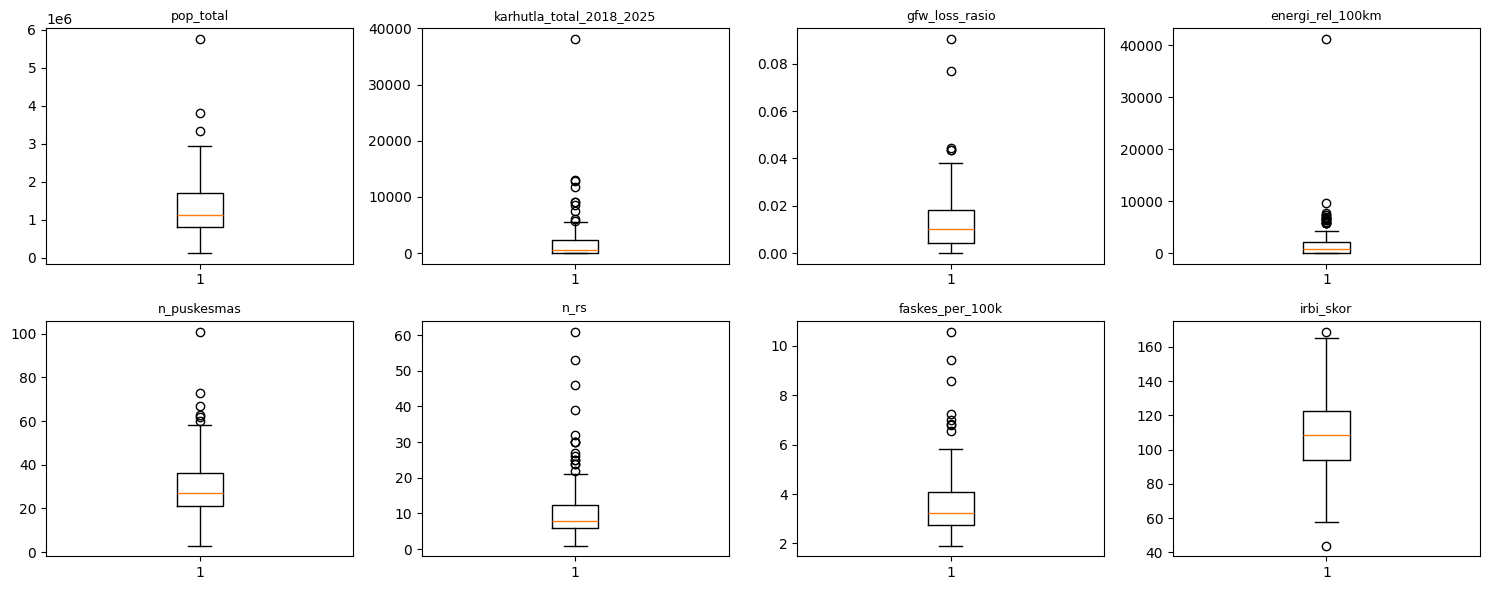

In [43]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, f in zip(axes.ravel(), ["pop_total", "karhutla_total_2018_2025", "gfw_loss_rasio", "energi_rel_100km",
                                "n_puskesmas", "n_rs", "faskes_per_100k", "irbi_skor"]):
    ax.boxplot(df[f])
    ax.set_title(f, fontsize=9)
plt.tight_layout(); plt.show()

## 5. Deteksi outlier multivariat (Isolation Forest dan LOF)
Outlier multivariat = wilayah yang **kombinasi** nilainya tidak biasa, walau tiap nilai sendiri mungkin biasa. Fitur yang sangat miring di-log dulu, lalu distandarkan agar skalanya setara.

In [44]:
X = df[FITUR].copy()
miring = X.columns[X.skew() > 1]
X[miring] = np.log1p(X[miring].clip(lower=0))
Xz = StandardScaler().fit_transform(X)

KONTAMINASI = 0.05
iso = IsolationForest(contamination=KONTAMINASI, random_state=42).fit(Xz)
df["outlier_iforest"] = iso.predict(Xz) == -1
lof = LocalOutlierFactor(n_neighbors=10, contamination=KONTAMINASI)
df["outlier_lof"] = lof.fit_predict(Xz) == -1
df["outlier_multi_kuat"] = df["outlier_iforest"] & df["outlier_lof"]
df["outlier_multi_salah_satu"] = df["outlier_iforest"] | df["outlier_lof"]

df["outlier_uni_jumlah"] = flag_uni.sum(axis=1)
print("Isolation Forest :", df.loc[df["outlier_iforest"], "NAME_2"].tolist())
print("LOF :", df.loc[df["outlier_lof"], "NAME_2"].tolist())
print("Ditandai keduanya:", df.loc[df["outlier_multi_kuat"], "NAME_2"].tolist())
print("Irisan kosong berarti kedua metode tidak sepakat: IF mencari titik yang mudah 'dipisahkan', LOF mencari titik yang jauh lebih jarang tetangganya dibanding sekitarnya.")
df.sort_values("outlier_uni_jumlah", ascending=False)[["NAME_2", "TYPE_2", "outlier_uni_jumlah", "outlier_iforest", "outlier_lof"]].head(10)

Isolation Forest : ['Bogor', 'Garut', 'Kota Sukabumi', 'Sukabumi', 'Kota Magelang']
LOF : ['Blora', 'Bojonegoro', 'Gresik', 'Pamekasan', 'Surabaya']
Ditandai keduanya: []
Irisan kosong berarti kedua metode tidak sepakat: IF mencari titik yang mudah 'dipisahkan', LOF mencari titik yang jauh lebih jarang tetangganya dibanding sekitarnya.


,NAME_2,TYPE_2,outlier_uni_jumlah,outlier_iforest,outlier_lof
24,Sukabumi,Kabupaten,6,True,False
6,Cianjur,Kabupaten,5,False,False
4,Bogor,Kabupaten,5,True,False
10,Garut,Kabupaten,5,True,False
26,Tasikmalaya,Kabupaten,5,False,False
13,Kota Bandung,Kota,4,False,False
0,Bandung,Kabupaten,4,False,False
15,Kota Bogor,Kota,3,False,False
7,Cimahi,Kota,3,False,False
21,Pangandaran,Kabupaten,3,False,False


### Keputusan penanganan outlier (isi alasanmu di laporan)
**Dipertahankan dan ditandai (diisolasi lewat kolom penanda), tidak dihapus.** Alasan yang bisa dipakai:
1. Nilai ekstrem di sini **nyata**, bukan salah input (contoh: kota besar berpenduduk jutaan, kab dengan kebakaran lahan luas). Lolos semua aturan validasi di bagian 2.
2. Tujuan project justru menemukan wilayah berisiko tinggi, dan itu sering wilayah yang ekstrem. Menghapusnya berarti menghapus temuan.
3. Hanya 100 wilayah, jadi menghapus beberapa saja mengubah hasil cukup besar.
4. Dampak outlier terhadap skala ditangani di tahap berikutnya lewat **transformasi log dan scaling yang robust**, bukan dengan membuang data.

Kalau dosen bertanya "kapan outlier dihapus?": kalau ada nilai yang melanggar aturan validasi (misal penduduk negatif), itu salah data dan dihapus atau diperbaiki. Di data ini tidak ada.

## 6. Laporan kualitas data: sebelum vs sesudah

In [45]:
def kualitas(d):
    ada_pelanggaran = cek_aturan(d).any(axis=1).sum()
    n_sel = d.shape[0] * d.shape[1]
    return {
        "jumlah baris": d.shape[0],
        "jumlah kolom": d.shape[1],
        "sel kosong": int(d.isna().sum().sum()),
        "persen sel kosong": round(d.isna().sum().sum() / n_sel * 100, 3),
        "baris duplikat": int(d.duplicated().sum()),
        "kode wilayah (CC_2) duplikat": int(d["CC_2"].duplicated().sum()),
        "baris melanggar aturan validasi": int(ada_pelanggaran),
    }

laporan = pd.DataFrame({"sebelum": kualitas(sebelum), "sesudah": kualitas(df)})
laporan.loc["wilayah ditandai outlier univariat di >= 1 fitur (tidak dihapus)"] = [np.nan, int((df["outlier_uni_jumlah"] > 0).sum())]
laporan.loc["wilayah ditandai outlier univariat di >= 3 fitur (tidak dihapus)"] = [np.nan, int((df["outlier_uni_jumlah"] >= 3).sum())]
laporan.loc["wilayah ditandai outlier multivariat oleh salah satu metode (tidak dihapus)"] = [np.nan, int(df["outlier_multi_salah_satu"].sum())]
laporan.loc["wilayah ditandai outlier multivariat oleh kedua metode (tidak dihapus)"] = [np.nan, int(df["outlier_multi_kuat"].sum())]
laporan.loc["wilayah diimputasi"] = [0, int(df["diimputasi"].sum())]
laporan

,sebelum,sesudah
jumlah baris,100.000,100.0
jumlah kolom,35.000,41.0
sel kosong,3.000,0.0
persen sel kosong,0.086,0.0
baris duplikat,0.000,0.0
kode wilayah (CC_2) duplikat,0.000,0.0
baris melanggar aturan validasi,0.000,0.0
wilayah ditandai outlier univariat di >= 1 fitur (tidak dihapus),NaN,59.0
wilayah ditandai outlier univariat di >= 3 fitur (tidak dihapus),NaN,16.0
wilayah ditandai outlier multivariat oleh salah satu metode (tidak dihapus),NaN,10.0


In [46]:
df.to_csv(OUT / "tahap2_clean.csv", index=False)
laporan.to_csv(OUT / "laporan_kualitas_data.csv")
print("tersimpan:", OUT / "tahap2_clean.csv", "| bentuk:", df.shape)

tersimpan: data/interim/tahap2_clean.csv | bentuk: (100, 41)


## Catatan untuk laporan
1. **Aturan validasi** (bagian 2): tulis daftar aturan dan hasilnya (0 pelanggaran berarti data masuk akal).
2. **Imputasi median per provinsi** untuk wilayah yang tidak ada di GFW, plus alasan dan keterbatasannya.
3. **Outlier dipertahankan dan ditandai**, dengan 4 alasan di atas. Sertakan boxplot dan daftar wilayah yang ditandai.
4. **Parameter yang perlu dijelaskan saat tanya jawab**: pengali IQR 1,5 dan 3, kontaminasi 5%, n_neighbors LOF = 10, log1p untuk fitur dengan skewness > 1.
5. **Masukkan juga temuan tahap 1 ke laporan kualitas data**: dari 933 gempa USGS hanya 168 yang jatuh di dalam polygon 3 provinsi; GFW hanya cocok 99 dari 100 kab/kota; angka karhutla berformat Indonesia ("1.284,70") harus dikonversi; baris provinsi dan "INDONESIA" dipisahkan dari data kab/kota.
6. Tahap 3: scaling, feature engineering, korelasi, dan seleksi fitur memakai `tahap2_clean.csv`.